In [1]:
import numpy as np
import matplotlib.pyplot as plt 
import matplotlib.animation as animation 
import pandas as pd 
import seaborn as sns 
import os

In [ ]:
# Data preparation and cleaning
raw_df = pd.read_csv('../Data/dataset.csv')
df = raw_df.copy()

# 1) Remove duplicate records
initial_rows = len(df)
df = df.drop_duplicates().copy()

# 2) Standardize column names and text fields
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].astype(str).str.strip()

text_cols = ['Gender', 'Area', 'AreaType', 'HouseType', 'District', 'Joint_Pain']
for col in text_cols:
    if col in df.columns:
        df[col] = df[col].str.title()

# 3) Convert categorical values to consistent format
if 'Outcome' in df.columns:
    df['Outcome'] = pd.to_numeric(df['Outcome'], errors='coerce')

# 4) Handle missing values conservatively
missing_before = df.isnull().sum().sum()
df = df.dropna().copy()
missing_after = df.isnull().sum().sum()

# 5) Create a readable label for the target variable
if 'Outcome' in df.columns:
    df['Outcome_Label'] = df['Outcome'].map({0: 'Negative', 1: 'Positive'})

# 6) Save the cleaned dataset for later reuse
cleaned_path = '../Data/dataset_cleaned.csv'
df.to_csv(cleaned_path, index=False)

print('Original rows:', initial_rows)
print('Rows after removing duplicates:', len(df))
print('Missing values before cleaning:', missing_before)
print('Missing values after cleaning:', missing_after)
print('Cleaned dataset saved to:', cleaned_path)
display(df.head(10))

df.shape

,Gender,Age,NS1,IgG,IgM,Area,AreaType,HouseType,District,Fever_Duration,Body_Temperature,Platelet_Count,WBC_Count,Joint_Pain,Headache,Retro_Orbital_Pain,Myalgia,Rash,Outcome
0,Female,45,0,0,0,Mirpur,Undeveloped,Building,Dhaka,2,38.6,129000,8300,Absent,0,0,0,0,0
1,Male,17,0,0,0,Chawkbazar,Developed,Building,Dhaka,4,38.2,325000,7900,Absent,0,0,0,0,0
2,Female,29,0,0,0,Paltan,Undeveloped,Other,Dhaka,6,37.2,309000,6400,Absent,0,0,1,0,0
3,Female,63,1,1,1,Motijheel,Developed,Other,Dhaka,4,39.1,51000,4500,Moderate,1,1,1,1,1
4,Male,22,0,0,0,Gendaria,Undeveloped,Building,Dhaka,4,37.4,185000,9100,Absent,1,0,0,0,0
5,Female,36,0,0,0,Dhanmondi,Developed,Other,Dhaka,1,38.0,164000,5000,Absent,0,0,0,0,0
6,Female,15,0,0,0,New Market,Undeveloped,Building,Dhaka,2,37.7,130000,4900,Moderate,0,1,0,0,0
7,Male,26,0,0,0,New Market,Developed,Other,Dhaka,0,38.1,232000,7700,Moderate,0,0,0,0,0
8,Female,31,0,0,0,Dhanmondi,Undeveloped,Tinshed,Dhaka,6,38.2,232000,4800,Absent,0,0,0,0,0
9,Female,10,0,0,0,Sher-e-Bangla Nagar,Developed,Tinshed,Dhaka,3,38.6,145000,11800,Absent,0,0,1,0,0


In [5]:
df.isnull().sum()

Gender                0
Age                   0
NS1                   0
IgG                   0
IgM                   0
Area                  0
AreaType              0
HouseType             0
District              0
Fever_Duration        0
Body_Temperature      0
Platelet_Count        0
WBC_Count             0
Joint_Pain            0
Headache              0
Retro_Orbital_Pain    0
Myalgia               0
Rash                  0
Outcome               0
dtype: int64

In [7]:


sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)


print('Dataset shape:', df.shape)
print('\nMissing values per column:')
print(df.isnull().sum())
print('\nQuick summary statistics:')
display(df.describe(include='all').T)


Dataset shape: (1000, 19)

Missing values per column:
Gender                0
Age                   0
NS1                   0
IgG                   0
IgM                   0
Area                  0
AreaType              0
HouseType             0
District              0
Fever_Duration        0
Body_Temperature      0
Platelet_Count        0
WBC_Count             0
Joint_Pain            0
Headache              0
Retro_Orbital_Pain    0
Myalgia               0
Rash                  0
Outcome               0
dtype: int64

Quick summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Gender,1000,2,Female,524,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,1000.0,NaN,NaN,NaN,35.924,16.468437,8.0,22.0,37.0,50.0,65.0
NS1,1000.0,NaN,NaN,NaN,0.519,0.499889,0.0,0.0,1.0,1.0,1.0
IgG,1000.0,NaN,NaN,NaN,0.533,0.499159,0.0,0.0,1.0,1.0,1.0
IgM,1000.0,NaN,NaN,NaN,0.475,0.499624,0.0,0.0,0.0,1.0,1.0
Area,1000,36,Jatrabari,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AreaType,1000,2,Developed,501,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HouseType,1000,3,Building,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
District,1000,1,Dhaka,1000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fever_Duration,1000.0,NaN,NaN,NaN,3.303,2.128314,0.0,2.0,3.0,5.0,7.0


/var/folders/j3/g588yn2d3hbbsjy0h548qc1r0000gn/T/ipykernel_88796/846884246.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='Set2')


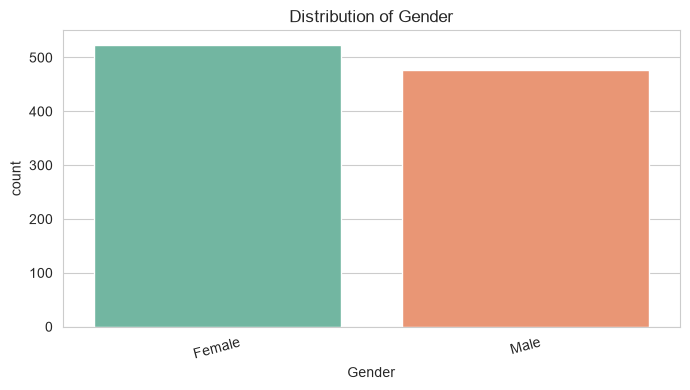

/var/folders/j3/g588yn2d3hbbsjy0h548qc1r0000gn/T/ipykernel_88796/846884246.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='Set2')


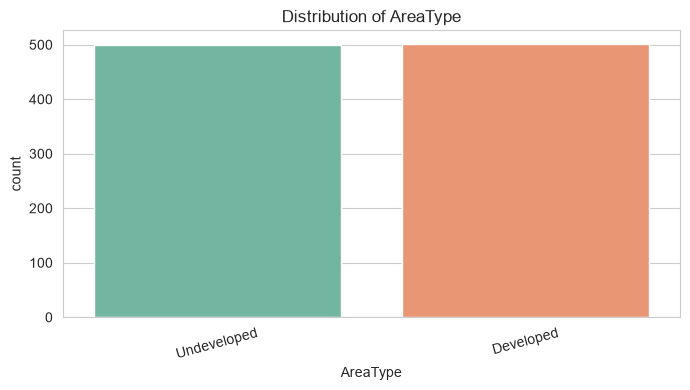

/var/folders/j3/g588yn2d3hbbsjy0h548qc1r0000gn/T/ipykernel_88796/846884246.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='Set2')


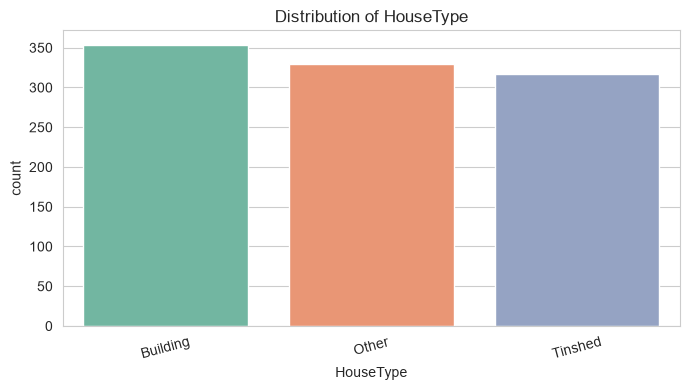

/var/folders/j3/g588yn2d3hbbsjy0h548qc1r0000gn/T/ipykernel_88796/846884246.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, palette='Set2')


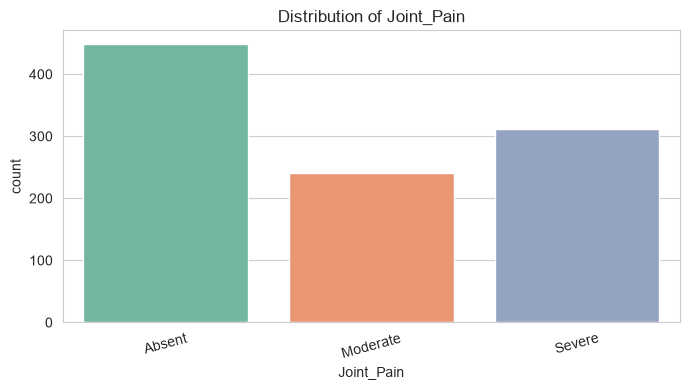


Categorical value counts:

Gender:
Gender
Female    524
Male      476
Name: count, dtype: int64

AreaType:
AreaType
Developed      501
Undeveloped    499
Name: count, dtype: int64

HouseType:
HouseType
Building    354
Other       329
Tinshed     317
Name: count, dtype: int64

Joint_Pain:
Joint_Pain
Absent      448
Severe      312
Moderate    240
Name: count, dtype: int64


In [8]:
# Categorical feature distributions
cat_cols = ['Gender', 'AreaType', 'HouseType', 'Joint_Pain']
for col in cat_cols:
    plt.figure(figsize=(7, 4))
    sns.countplot(data=df, x=col, palette='Set2')
    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

print('\nCategorical value counts:')
for col in cat_cols:
    print(f'\n{col}:')
    print(df[col].value_counts())


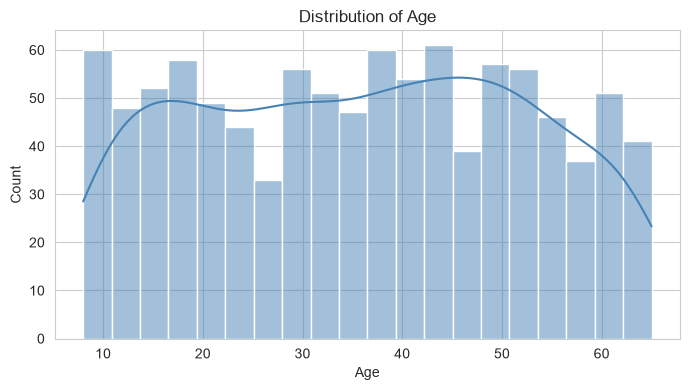

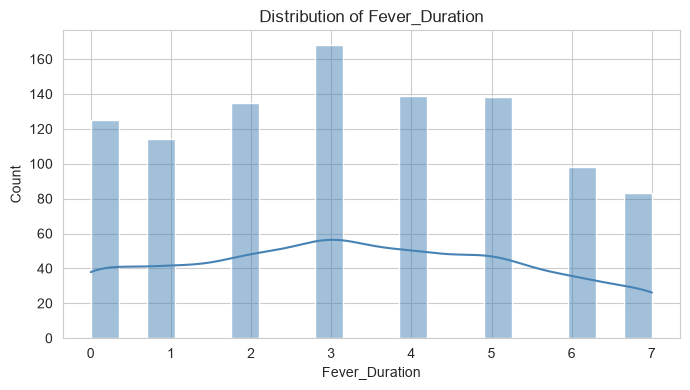

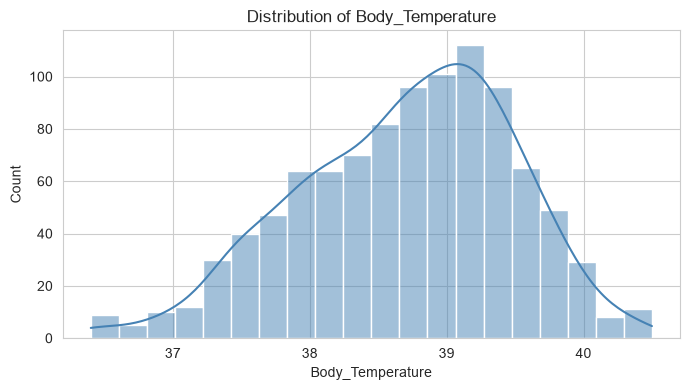

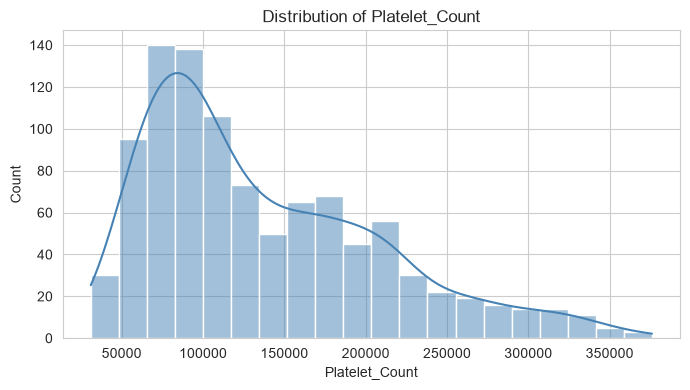

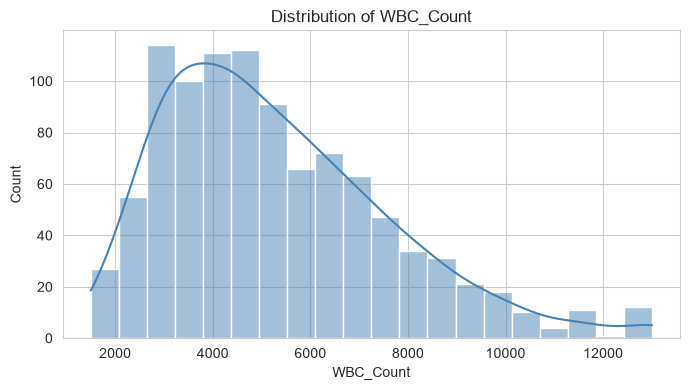


Outcome summary by key clinical measures:
           Age  Fever_Duration  Body_Temperature  Platelet_Count  WBC_Count
Outcome                                                                    
0        36.13            2.01             38.33       189931.48    6771.95
1        35.74            4.44             39.02        91378.99    4024.02


/var/folders/j3/g588yn2d3hbbsjy0h548qc1r0000gn/T/ipykernel_88796/93555456.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Outcome', y=col, palette='pastel')


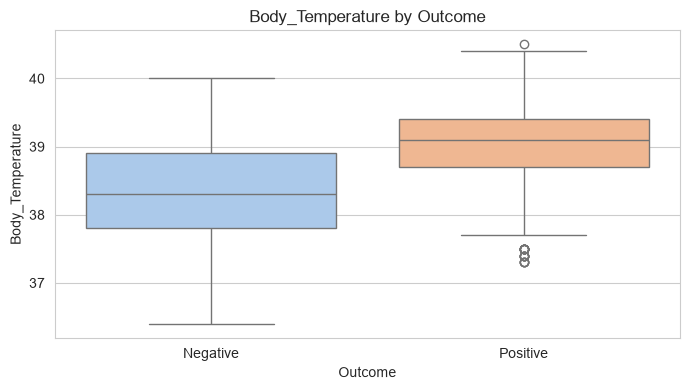

/var/folders/j3/g588yn2d3hbbsjy0h548qc1r0000gn/T/ipykernel_88796/93555456.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Outcome', y=col, palette='pastel')


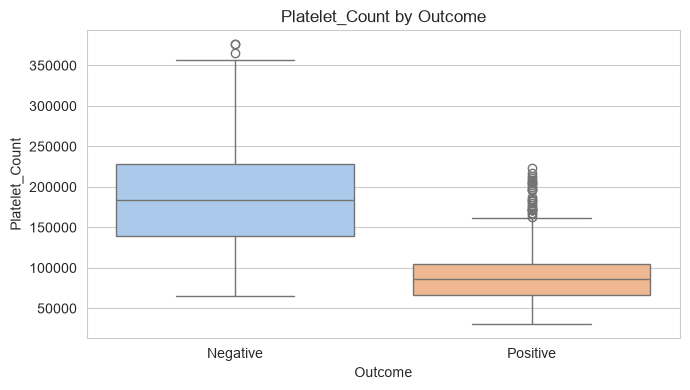

/var/folders/j3/g588yn2d3hbbsjy0h548qc1r0000gn/T/ipykernel_88796/93555456.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Outcome', y=col, palette='pastel')


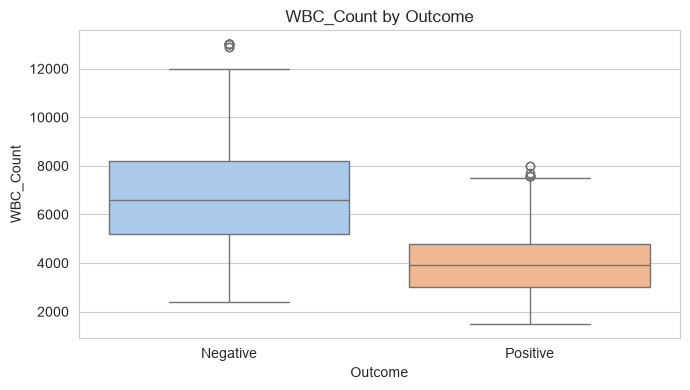

In [12]:
# Numerical feature distribution and outcome comparison
num_cols = ['Age', 'Fever_Duration', 'Body_Temperature', 'Platelet_Count', 'WBC_Count']

for col in num_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col], kde=True, bins=20, color='steelblue')
    plt.title(f'Distribution of {col}')
    plt.tight_layout()
    plt.show()

print('\nOutcome summary by key clinical measures:')
print(df.groupby('Outcome')[num_cols].mean().round(2))

for col in ['Body_Temperature', 'Platelet_Count', 'WBC_Count']:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x='Outcome', y=col, palette='pastel')
    plt.title(f'{col} by Outcome')
    plt.xticks([0, 1], ['Negative', 'Positive'])
    plt.tight_layout()
    plt.show()


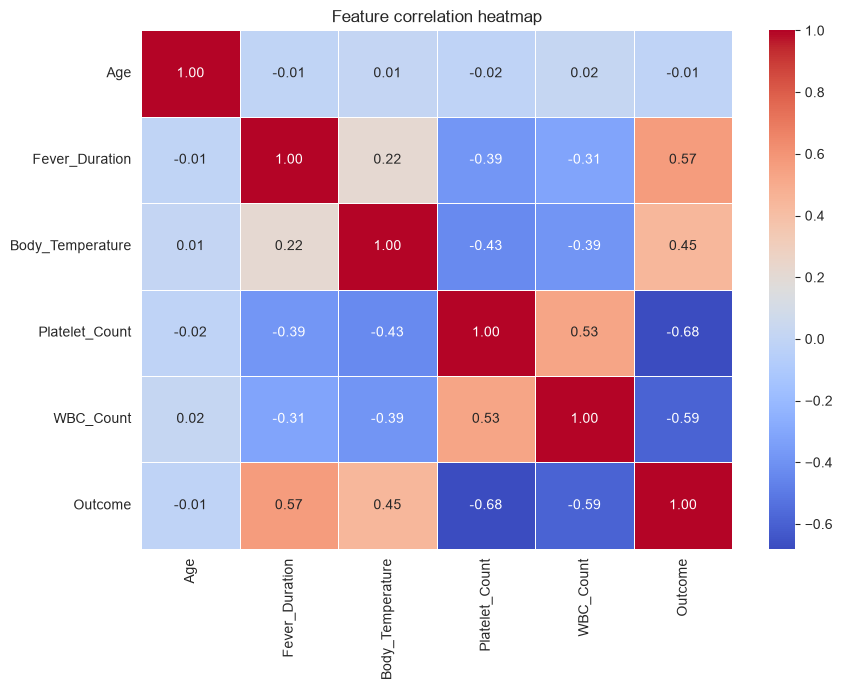


Correlation with Outcome:
Outcome             1.000
Fever_Duration      0.569
Body_Temperature    0.448
Age                -0.012
WBC_Count          -0.593
Platelet_Count     -0.681
Name: Outcome, dtype: float64


In [10]:
# Correlation heatmap
corr = df[['Age', 'Fever_Duration', 'Body_Temperature', 'Platelet_Count', 'WBC_Count', 'Outcome']].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature correlation heatmap')
plt.tight_layout()
plt.show()

print('\nCorrelation with Outcome:')
print(corr['Outcome'].sort_values(ascending=False).round(3))


In [11]:
# Key findings summary
print('Outcome proportion:')
print(df['Outcome'].value_counts(normalize=True).round(3))
print('\nOutcome rate by gender:')
print(df.groupby('Gender')['Outcome'].mean().round(3))
print('\nOutcome rate by area type:')
print(df.groupby('AreaType')['Outcome'].mean().round(3))
print('\nOutcome rate by joint pain severity:')
print(df.groupby('Joint_Pain')['Outcome'].mean().round(3))
print('\nClinical interpretation:')
print('- The dataset is well balanced in gender and area type, with no missing values.')
print('- The overall dengue-positive rate is about 53%.')
print('- Higher fever duration and temperature are associated with positive outcomes.')
print('- Platelet counts are notably lower in positive cases, while WBC counts also trend downward.')
print('- Severe joint pain shows a much higher positive rate than absent joint pain.')


Outcome proportion:
Outcome
1    0.533
0    0.467
Name: proportion, dtype: float64

Outcome rate by gender:
Gender
Female    0.536
Male      0.529
Name: Outcome, dtype: float64

Outcome rate by area type:
AreaType
Developed      0.513
Undeveloped    0.553
Name: Outcome, dtype: float64

Outcome rate by joint pain severity:
Joint_Pain
Absent      0.170
Moderate    0.667
Severe      0.952
Name: Outcome, dtype: float64

Clinical interpretation:
- The dataset is well balanced in gender and area type, with no missing values.
- The overall dengue-positive rate is about 53%.
- Higher fever duration and temperature are associated with positive outcomes.
- Platelet counts are notably lower in positive cases, while WBC counts also trend downward.
- Severe joint pain shows a much higher positive rate than absent joint pain.


In [ ]:
# Model training, tuning, and best-model selection
# ---------------------------------------------------
# We compare multiple classifiers and tune their hyperparameters.
# For the neural-network model, we tune the hidden layer sizes,
# learning rate, and regularization strength; a Keras/TensorFlow
# network can also add dropout and batch normalization for extra
# regularization.

import warnings
warnings.filterwarnings('ignore')

import os
import pandas as pd
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# 1) Load cleaned data
os.makedirs('../Models', exist_ok=True)
df = pd.read_csv('../Data/dataset_cleaned.csv')

feature_cols = [col for col in df.columns if col not in ['Outcome', 'Outcome_Label']]
X = df[feature_cols].copy()
y = df['Outcome'].astype(int)

cat_cols = X.select_dtypes(include=['object']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object']).columns.tolist()

# 2) Train / test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3) Preprocessing for numeric + categorical features
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])

# 4) Define candidate models and parameter grids
models = {
    'logistic_regression': {
        'estimator': LogisticRegression(max_iter=1000, random_state=42),
        'params': {
            'model__C': [0.1, 1, 10],
            'model__solver': ['liblinear', 'lbfgs']
        }
    },
    'random_forest': {
        'estimator': RandomForestClassifier(random_state=42),
        'params': {
            'model__n_estimators': [200, 400],
            'model__max_depth': [None, 8, 12],
            'model__min_samples_leaf': [1, 2]
        }
    },
    'gradient_boosting': {
        'estimator': GradientBoostingClassifier(random_state=42),
        'params': {
            'model__n_estimators': [100, 200],
            'model__learning_rate': [0.05, 0.1],
            'model__max_depth': [2, 3],
            'model__subsample': [0.8, 1.0]
        }
    },
    'svc': {
        'estimator': SVC(probability=True, random_state=42),
        'params': {
            'model__C': [0.1, 1, 10],
            'model__gamma': ['scale', 'auto'],
            'model__kernel': ['rbf', 'linear']
        }
    },
    'mlp_classifier': {
        'estimator': MLPClassifier(random_state=42, max_iter=500),
        'params': {
            'model__hidden_layer_sizes': [(32,), (64,), (32, 16)],
            'model__learning_rate_init': [0.001, 0.01],
            'model__alpha': [0.0001, 0.001],
            'model__activation': ['relu', 'tanh']
        }
    }
}

# 5) Train and tune each model using cross-validation
comparison = []
best_estimators = {}
for name, config in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', config['estimator'])
    ])

    search = GridSearchCV(
        pipeline,
        config['params'],
        cv=5,
        scoring='f1',
        n_jobs=-1,
        verbose=0,
    )
    search.fit(X_train, y_train)

    preds = search.best_estimator_.predict(X_test)
    proba = search.best_estimator_.predict_proba(X_test)[:, 1]

    result = {
        'Model': name,
        'Best_CV_F1': round(search.best_score_, 4),
        'Test_Accuracy': round(accuracy_score(y_test, preds), 4),
        'Test_Precision': round(precision_score(y_test, preds, zero_division=0), 4),
        'Test_Recall': round(recall_score(y_test, preds, zero_division=0), 4),
        'Test_F1': round(f1_score(y_test, preds, zero_division=0), 4),
        'ROC_AUC': round(roc_auc_score(y_test, proba), 4),
        'Best_Params': search.best_params_
    }
    comparison.append(result)
    best_estimators[name] = search.best_estimator_

    print(f"{name}: cv_f1={result['Best_CV_F1']}, test_f1={result['Test_F1']}, roc_auc={result['ROC_AUC']}")
    print('Best params:', result['Best_Params'])
    print('-' * 60)

comparison_df = pd.DataFrame(comparison).sort_values(
    ['Test_F1', 'Best_CV_F1'], ascending=[False, False]
).reset_index(drop=True)

print('\nFinal model ranking:')
print(comparison_df[['Model', 'Best_CV_F1', 'Test_Accuracy', 'Test_F1', 'ROC_AUC']].to_string(index=False))

# 6) Select the best model by F1 score and then by cross-validation F1
best_name = comparison_df.iloc[0]['Model']
best_model = best_estimators[best_name]

# Save the best model for reuse in later predictions
joblib.dump({'model': best_model, 'feature_columns': feature_cols, 'model_name': best_name, 'metrics': comparison_df.iloc[0].to_dict()}, '../Models/best_dengue_model.joblib')

print('\nBest model selected:', best_name)
print('Saved model path: ../Models/best_dengue_model.joblib')
